# RoadScan 
The approved dataset is RoadScan_Dataset_Final/RoadScan_Dataset: 6404 training, 797 validation, 799 RDD test, and 100 separate Saudi test images. All prepared images are RGB 640x640. No earlier local dataset is loaded or required.

This notebook checks images, normalized bounding boxes, class counts, current dataset_version.json, exact file/pixel fingerprints, duplicates and available scene-group overlap. Optional previews and dataset path configurations are provided. No training, automatic semantic relabeling or source-image rewriting is performed.

All splits use the same four IDs: 0 longitudinal_crack, 1 transverse_crack, 2 alligator_crack, 3 pothole. Saudi100 is external test only; do not use it for training or threshold selection. Its supplied metadata describes AI-reviewed draft annotations requiring independent human confirmation. Structural PASS does not certify annotation completeness or physical scene independence.


In [ ]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs' / 'project.example.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the RoadScan_GitHub folder.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from roadscan.settings import load_settings
settings = load_settings(ROOT)


## 1. Dependencies
Install the packages used by this notebook.

In [ ]:
# Install image reading, tables, previews and YAML support.
%pip install -q pillow pandas matplotlib pyyaml

Note: you may need to restart the kernel to use updated packages.


## 2. Settings and preparation metadata
Change DATA_ROOT only if the prepared dataset moves. For Colab, mount Drive and enter the Drive folder path.

In [3]:
# Import standard-library tools and the required image libraries.
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import hashlib
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import yaml
from IPython.display import display

# Optional in Colab: mount Drive before setting DATA_ROOT.
# from google.colab import drive
# drive.mount("/content/drive")
DATA_ROOT = settings['dataset_root']
WORKERS = 8
SHOW_PREVIEWS = True
EXPECTED_SIZES = {"train": (640, 640), "val": (640, 640), "test": (640, 640), "saudi_test": (640, 640)}
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = ("train", "val", "test", "saudi_test")
RDD_NAMES = {0: "longitudinal_crack", 1: "transverse_crack", 2: "alligator_crack", 3: "pothole"}
LOCAL_NAMES = RDD_NAMES.copy()  # Reviewed local labels now use the same four IDs.

# Use the correct label schema for each source.
def names_for(split):
    return LOCAL_NAMES if split == "saudi_test" else RDD_NAMES

def portable(value):
    return str(value).replace(chr(92), "/")

# Load original preparation records for integrity and expected-count checks.
version_info = json.loads((DATA_ROOT / "dataset_version.json").read_text(encoding="utf-8"))
report = {"split_images": {s: int(v["images"]) for s, v in version_info["splits"].items()}}
integrity = json.loads((DATA_ROOT / "integrity_sha256.json").read_text(encoding="utf-8"))
metadata = {}
for line in (DATA_ROOT / "manifest.jsonl").read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    row = json.loads(line)
    key = portable(row["image"])
    if key in metadata or Path(key).is_absolute() or ".." in Path(key).parts:
        raise ValueError(f"Duplicate or invalid manifest image path: {key}")
    metadata[key] = row
print("Approved dataset:", version_info["version"])
print("Manifest images:", len(metadata))


Approved dataset: RoadScan-RDD8000-Saudi100-2026-10-26
Manifest images: 8100


## 3. Image and label checks
Validate RGB, the expected dimensions for each split, four-class normalized box coordinates and preparation metadata. Tiny coordinate overflow up to 0.00001 is tolerated in memory only.

In [4]:
# Read normalized class-and-box labels and convert valid boxes to pixel coordinates.
def read_boxes(path, size, names):
    width, height = size
    boxes = []
    for number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not line.strip():
            continue
        fields = line.split()
        if len(fields) != 5:
            raise ValueError(f"Line {number}: expected five class-and-box fields")
        cls = int(fields[0])
        x, y, w, h = map(float, fields[1:])
        if cls not in names or not all(math.isfinite(v) for v in (x, y, w, h)):
            raise ValueError(f"Line {number}: invalid class or non-finite coordinate")
        if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            raise ValueError(f"Line {number}: invalid normalized coordinates")
        edges = (x-w/2, y-h/2, x+w/2, y+h/2)
        if min(edges) < -1e-5 or max(edges) > 1+1e-5:
            raise ValueError(f"Line {number}: box exceeds image boundaries")
        x1, y1, x2, y2 = [min(1, max(0, v)) for v in edges]
        box = (cls, x1*width, y1*height, x2*width, y2*height)
        if box in boxes:
            raise ValueError(f"Line {number}: duplicate box")
        boxes.append(box)
    return boxes

# Validate one prepared pair and its manifest entry without changing files.
def inspect(task):
    split, image_path, label_path = task
    relative = image_path.relative_to(DATA_ROOT).as_posix()
    try:
        row = metadata[relative]
        domain = "local" if split == "saudi_test" else "rdd"
        if row["split"] != split or row["domain"] != domain:
            raise ValueError("Manifest split or domain mismatch")
        if portable(row["label"]) != label_path.relative_to(DATA_ROOT).as_posix():
            raise ValueError("Manifest label path mismatch")
        with Image.open(image_path) as image:
            image.load()
            if image.mode != "RGB" or image.size != EXPECTED_SIZES[split]:
                raise ValueError("Unexpected prepared image mode or dimensions for this split")
            if image.getexif().get(274, 1) != 1:
                raise ValueError("Unapplied EXIF orientation")
            digest = hashlib.sha256(f"{image.width},{image.height}".encode() + image.tobytes()).hexdigest()
            boxes = read_boxes(label_path, image.size, names_for(split))
        if digest != row["export_pixel_sha256"]:
            raise ValueError("Image pixels differ from preparation metadata")
        if [sum(b[0] == c for b in boxes) for c in names_for(split)] != row["class_counts"]:
            raise ValueError("Label counts differ from preparation metadata")
        if "known_annotation_classes" in row and row["known_annotation_classes"] != list(names_for(split)):
            raise ValueError("Manifest annotation schema mismatch")
        # Verify exact image/label bytes against the approved version manifest.
        for member in (image_path, label_path):
            key = member.relative_to(DATA_ROOT).as_posix()
            if key not in integrity or hashlib.sha256(member.read_bytes()).hexdigest() != integrity[key]:
                raise ValueError(f"Approved file fingerprint mismatch: {key}")
        return dict(split=split, relative=relative, image_path=image_path,
                    boxes=boxes, sha256=digest, group=row.get("scene_group")), None
    except (OSError, ValueError, KeyError, TypeError) as exc:
        return None, dict(path=relative, issue=str(exc))


## 4. Check all splits
Scan every image-label pair and detect missing images, missing labels, orphan labels and repeated image stems. Empty labels are summarized once rather than displayed as hundreds of warnings.

In [5]:
# Build paired-file tasks and check directory consistency.
tasks, errors = [], []
found = Counter()
seen_images = set()
for split in SPLITS:
    image_dir, label_dir = DATA_ROOT / "images" / split, DATA_ROOT / "labels" / split
    if not image_dir.is_dir() or not label_dir.is_dir():
        errors.append(dict(path=split, issue="Missing images or labels directory"))
    images = sorted(p for p in image_dir.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS)
    found[split] = len(images)
    stems, expected_labels = set(), set()
    for path in images:
        stem = path.relative_to(image_dir).with_suffix("").as_posix()
        if stem in stems:
            errors.append(dict(path=str(path), issue="Duplicate image stem"))
        stems.add(stem)
        label = label_dir / path.relative_to(image_dir).with_suffix(".txt")
        expected_labels.add(label)
        seen_images.add(path.relative_to(DATA_ROOT).as_posix())
        tasks.append((split, path, label))
    for label in label_dir.rglob("*.txt"):
        if label not in expected_labels:
            errors.append(dict(path=str(label), issue="Label without image"))
for missing in sorted(set(metadata) - seen_images):
    errors.append(dict(path=missing, issue="Manifest image missing from disk"))

# Decode images and validate annotations in parallel.
records = []
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for index, (record, error) in enumerate(pool.map(inspect, tasks), 1):
        if record is not None:
            records.append(record)
        if error is not None:
            errors.append(error)
        if index % 2000 == 0 or index == len(tasks):
            print(f"Checked {index}/{len(tasks)} images")

# Check exact duplicates and overlap of available scene groups.
hashes, groups = {}, defaultdict(set)
for record in records:
    digest = record["sha256"]
    if digest in hashes:
        errors.append(dict(path=record["relative"], issue="Exact duplicate of " + hashes[digest]))
    hashes[digest] = record["relative"]
    if record["group"]:
        groups[record["group"]].add(record["split"])
for group, splits in groups.items():
    if len(splits) > 1:
        errors.append(dict(path=str(group), issue=f"Group overlaps splits: {sorted(splits)}"))

# Summarize pairs, boxes and empty labels for each split.
summary_rows, class_rows = [], []
for split in SPLITS:
    subset = [r for r in records if r["split"] == split]
    expected = report["split_images"][split]
    if len(subset) != expected:
        errors.append(dict(path=split, issue=f"Expected {expected} valid pairs, found {len(subset)}"))
    summary_rows.append(dict(split=split, images_found=found[split], valid_pairs=len(subset),
                             boxes=sum(len(r["boxes"]) for r in subset),
                             empty_labels=sum(not r["boxes"] for r in subset)))
    for cls, name in names_for(split).items():
        boxes = sum(b[0] == cls for r in subset for b in r["boxes"])
        class_rows.append(dict(split=split, class_name=name,
                               images=sum(any(b[0] == cls for b in r["boxes"]) for r in subset), boxes=boxes))
        if split != "saudi_test" and boxes == 0:
            errors.append(dict(path=split, issue=f"Missing RDD class: {name}"))
display(pd.DataFrame(summary_rows))
display(pd.DataFrame(class_rows))
if errors:
    display(pd.DataFrame(errors).head(30))
structurally_ready = bool(records) and not errors
print("Structural validation:", "PASS" if structurally_ready else "FIX ERRORS")
print("Errors:", len(errors))



Checked 2000/8100 images
Checked 4000/8100 images
Checked 6000/8100 images
Checked 8000/8100 images
Checked 8100/8100 images


,split,images_found,valid_pairs,boxes,empty_labels
0,train,6404,6404,11662,0
1,val,797,797,1433,0
2,test,799,799,1437,0
3,saudi_test,100,100,195,0


,split,class_name,images,boxes
0,train,longitudinal_crack,1959,2972
1,train,transverse_crack,1907,2883
2,train,alligator_crack,1961,2916
3,train,pothole,1908,2891
4,val,longitudinal_crack,238,357
5,val,transverse_crack,239,357
6,val,alligator_crack,240,360
7,val,pothole,239,359
8,test,longitudinal_crack,240,360
9,test,transverse_crack,240,360


Structural validation: PASS
Errors: 0


## 5. Optional visual preview
Inspect a few samples from each split for box placement and orientation. Set SHOW_PREVIEWS=False to skip. This does not modify files.

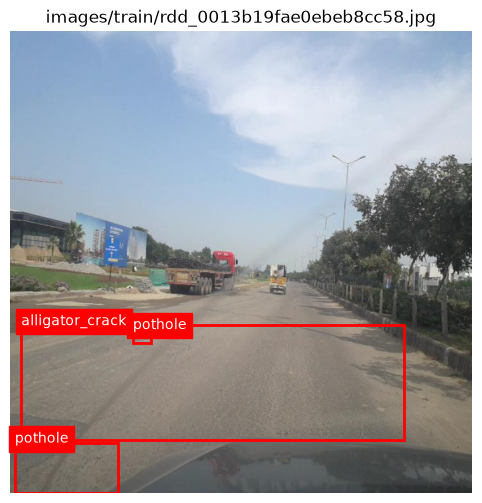

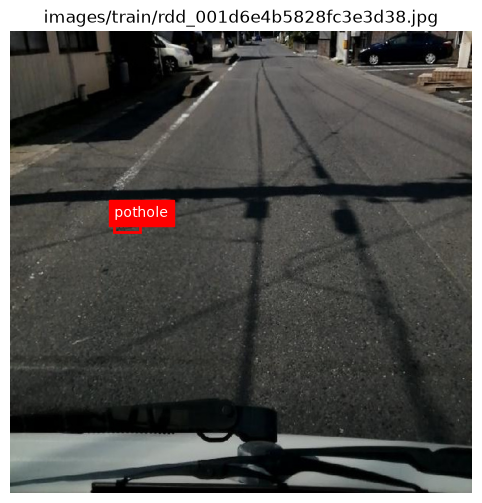

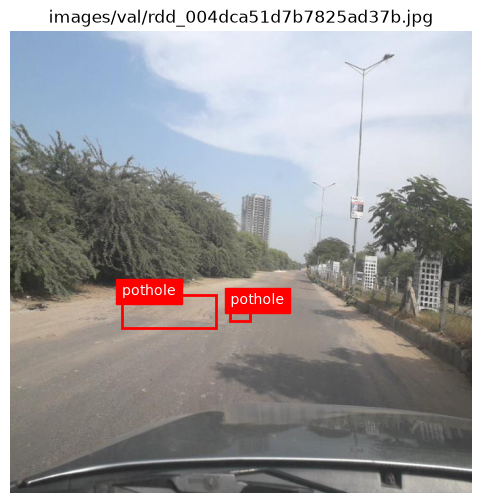

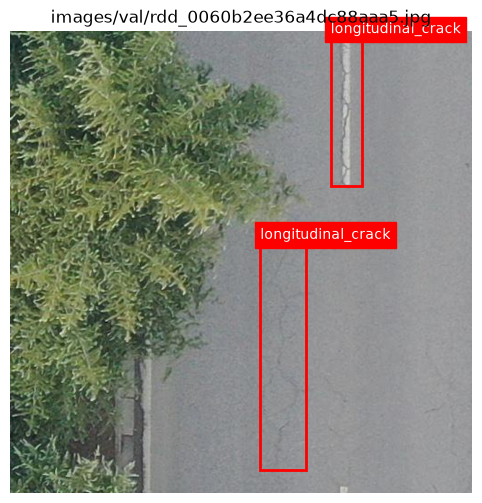

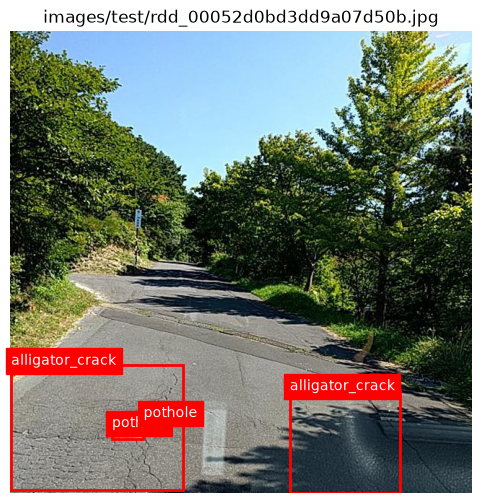

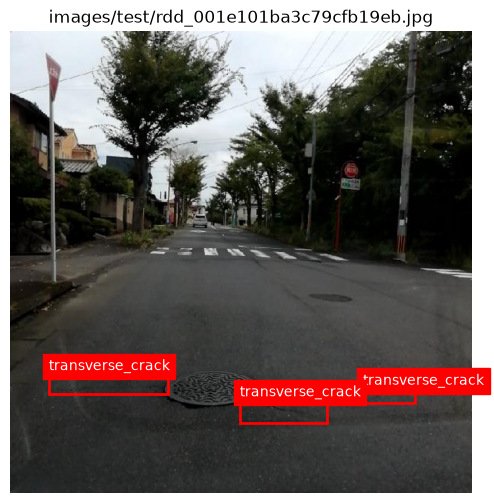

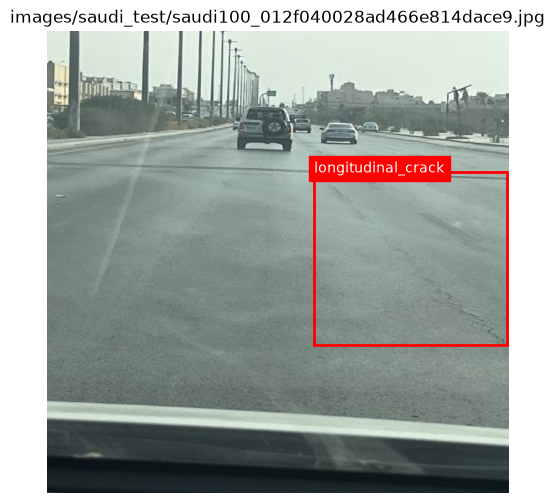

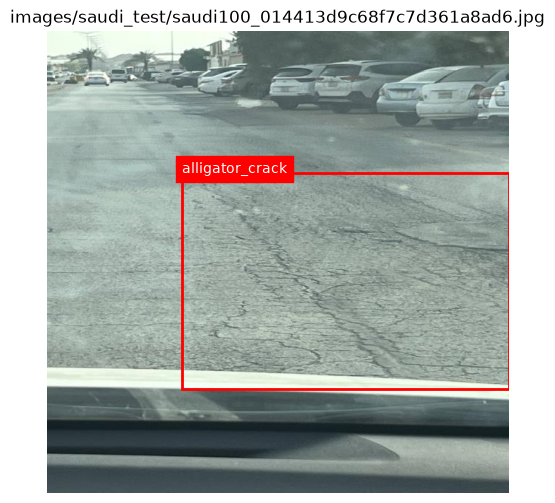

In [6]:
# Display each source with its own class names.
if SHOW_PREVIEWS:
    for split in SPLITS:
        for record in [r for r in records if r["split"] == split][:2]:
            with Image.open(record["image_path"]) as image:
                fig, ax = plt.subplots(figsize=(8, 6))
                ax.imshow(image)
                for cls, x1, y1, x2, y2 in record["boxes"]:
                    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                              fill=False, edgecolor="red", linewidth=2))
                    ax.text(x1, y1, names_for(split)[cls], color="white", backgroundcolor="red")
                ax.set_title(record["relative"])
                ax.axis("off")
                plt.show()
                plt.close(fig)


## 6. Save dataset configurations
Save the RDD and local test YAML files with the same four-class schema. RDD training/validation paths remain identical; the test image folder differs. No image export or model training is performed.

In [7]:
# Stop before saving paths when any structural check fails.
if not structurally_ready:
    raise RuntimeError("Fix the reported data errors before starting the baseline.")

# Use the same four-class schema for RDD and the reviewed local test.
configs = {
    "data.yaml": dict(path=str(DATA_ROOT), train="images/train", val="images/val",
                      test="images/test", names=RDD_NAMES),
    "saudi.yaml": dict(path=str(DATA_ROOT), train="images/train", val="images/val", test="images/saudi_test", nc=4, names=LOCAL_NAMES),
}
for filename, config in configs.items():
    path = DATA_ROOT / filename
    if not path.is_file() or yaml.safe_load(path.read_text(encoding="utf-8")) != config:
        path.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
print("RDD baseline configuration:", DATA_ROOT / "data.yaml")
print("Local collection configuration:", DATA_ROOT / "saudi.yaml")
print("Images and annotations were not changed.")
print("Local labels now match RDD IDs. Evaluate this split separately; never tune on it.")


RDD baseline configuration: C:\Users\ASUS\Downloads\RoadScan_Detection_GitHub\RoadScan_GitHub\RoadScan_Dataset_Final\RoadScan_Dataset\data.yaml
Local collection configuration: C:\Users\ASUS\Downloads\RoadScan_Detection_GitHub\RoadScan_GitHub\RoadScan_Dataset_Final\RoadScan_Dataset\saudi.yaml
Images and annotations were not changed.
Local labels now match RDD IDs. Evaluate this split separately; never tune on it.
